# ProcureGuard pipeline review

This notebook only reads files the analysis pipeline has already written. It does not detect fraud again and it does not change a score. Every record is synthetic. Every alert is Pending Review until a person changes that status. There is no web application and no Power BI PBIX file in this project.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 88)
summary = json.loads((root / 'reports' / 'run_summary.json').read_text(encoding='utf-8'))
alerts = pd.read_csv(root / 'data' / 'processed' / 'audit_alerts.csv')
scores = pd.read_csv(root / 'data' / 'processed' / 'vendor_risk_scores.csv')
invoices = pd.read_csv(root / 'data' / 'raw' / 'invoices.csv')
checks = pd.read_csv(root / 'data' / 'processed' / 'data_quality_checks.csv')
failures = pd.read_csv(root / 'data' / 'processed' / 'data_quality_failures.csv')
metrics = pd.read_csv(root / 'data' / 'evaluation' / 'rule_metrics.csv')
print('generated_at', summary['generated_at'])
print('alerts', int(summary['alerts']), 'vendors_scored', int(summary['vendors_scored']))

generated_at 2026-10-31 16:38:20
alerts 230 vendors_scored 60


## Executive overview

<a id="executive-overview"></a>

Counts and exposure come from the latest `analyze` run. Positive invoice totals are summed from the raw synthetic file.

,measure,value
0,Invoices in the raw file,1500.00
1,Positive procurement spend (INR),65951747.62
2,Alerts,230.00
3,Alerts pending review,230.00
4,Potential exposure (INR),14795731.20
5,Vendors scored,60.00
6,High or critical vendors,0.00
7,Data-quality pass rate,0.50


,risk_category,vendors
0,Low,52
1,Medium,8


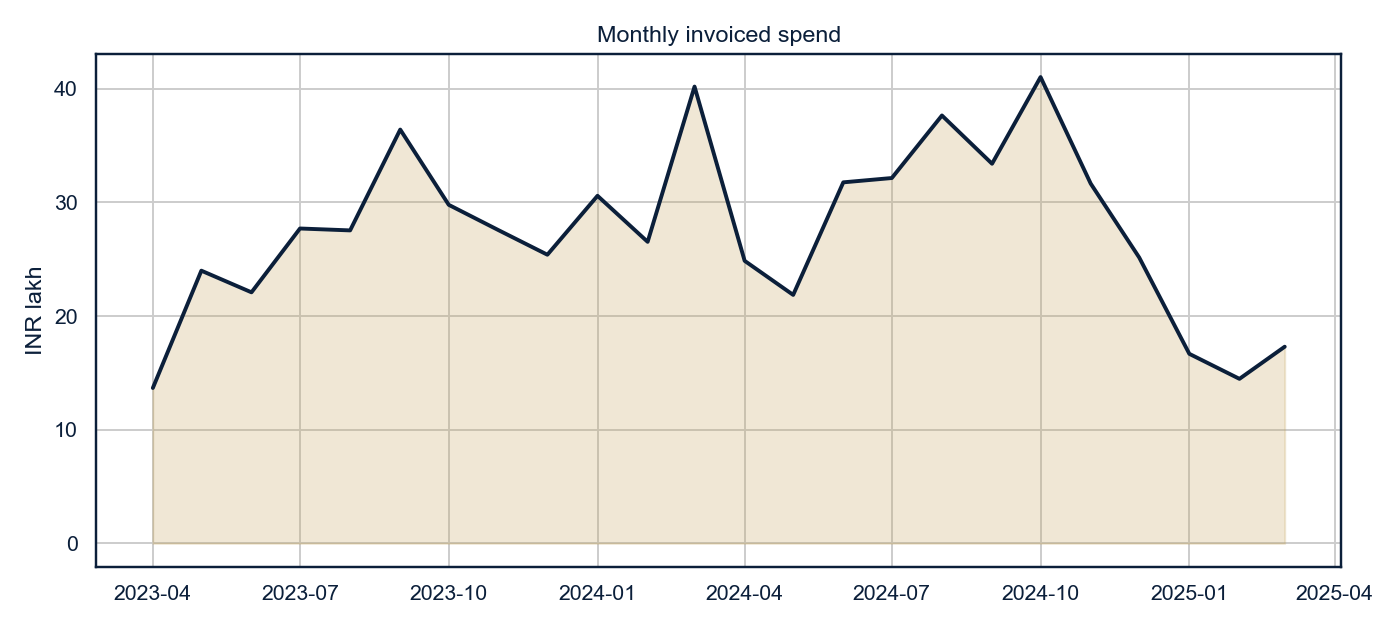

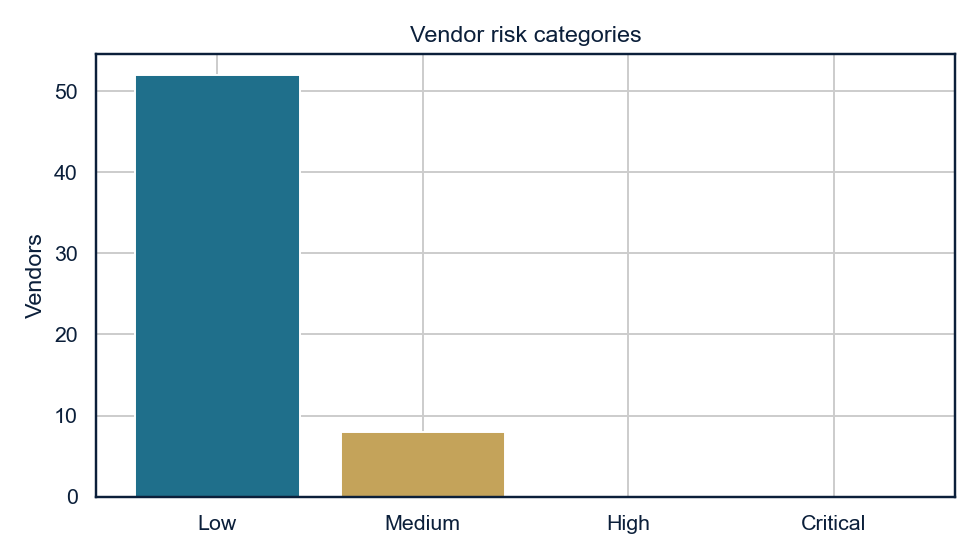

In [2]:
positive = pd.to_numeric(invoices['total_amount_inr'], errors='coerce')
spend = float(positive[positive > 0].sum())
overview = pd.DataFrame([
    ['Invoices in the raw file', int(len(invoices))],
    ['Positive procurement spend (INR)', round(spend, 2)],
    ['Alerts', int(summary['alerts'])],
    ['Alerts pending review', int((alerts['review_status'] == 'Pending Review').sum())],
    ['Potential exposure (INR)', float(summary['potential_exposure_inr'])],
    ['Vendors scored', int(summary['vendors_scored'])],
    ['High or critical vendors', int(summary['high_or_critical_vendors'])],
    ['Data-quality pass rate', float(summary['data_quality_pass_rate'])],
], columns=['measure', 'value'])
display(overview)
display(scores['risk_category'].value_counts().rename_axis('risk_category').reset_index(name='vendors'))
display(Image(filename=str(root / 'screenshots' / '01_monthly_spend.png')))
display(Image(filename=str(root / 'screenshots' / '03_vendor_risk_distribution.png')))

## Fraud alerts

<a id="fraud-alerts"></a>

Invoice-level alerts from `audit_alerts.csv`. Exposure on the anchor copy of a duplicate pair is zero so the pair is not added twice. Review status is still Pending Review.

In [3]:
totals = invoices[['invoice_id', 'total_amount_inr']].copy()
totals['total_amount_inr'] = pd.to_numeric(totals['total_amount_inr'], errors='coerce')
invoice_alerts = alerts[alerts['entity_type'] == 'invoice'].merge(
    totals, left_on='entity_id', right_on='invoice_id', how='left'
)
columns = ['alert_id', 'rule_name', 'entity_id', 'vendor_id', 'total_amount_inr', 'estimated_exposure_inr', 'severity', 'review_status']
display(invoice_alerts[columns].head(12))
print('invoice_alerts', len(invoice_alerts), 'of', len(alerts), 'alerts')

,alert_id,rule_name,entity_id,vendor_id,total_amount_inr,estimated_exposure_inr,severity,review_status
0,ALT000059,Exact duplicate invoice number,INV000240,VEN052,49560.0,0.0,High,Pending Review
1,ALT000060,Exact duplicate invoice number,INV000241,VEN052,49560.0,49560.0,High,Pending Review
2,ALT000061,Exact duplicate invoice number,INV000242,VEN053,51625.0,0.0,High,Pending Review
3,ALT000062,Exact duplicate invoice number,INV000243,VEN053,51625.0,51625.0,High,Pending Review
4,ALT000063,Exact duplicate invoice number,INV000244,VEN054,53690.0,0.0,High,Pending Review
5,ALT000064,Exact duplicate invoice number,INV000245,VEN054,53690.0,53690.0,High,Pending Review
6,ALT000065,Exact duplicate invoice number,INV000246,VEN055,55755.0,0.0,High,Pending Review
7,ALT000066,Exact duplicate invoice number,INV000247,VEN055,55755.0,55755.0,High,Pending Review
8,ALT000067,Exact duplicate invoice number,INV000248,VEN056,57820.0,0.0,High,Pending Review
9,ALT000068,Exact duplicate invoice number,INV000249,VEN056,57820.0,57820.0,High,Pending Review


invoice_alerts 52 of 230 alerts


## Vendor risk

<a id="vendor-risk"></a>

The 0–100 score and category are the pipeline output. Factor columns are the observed rates, not the weighted points.

In [4]:
risk_columns = [
    'vendor_id', 'vendor_name', 'vendor_category', 'risk_score', 'risk_category',
    'raw_duplicate_invoice_rate', 'raw_dispute_rate', 'raw_price_volatility',
    'raw_split_purchase_involvement', 'raw_po_approval_violations', 'raw_payment_anomaly_rate',
]
display(scores.sort_values('risk_score', ascending=False)[risk_columns].head(10))
print('highest_score', float(scores['risk_score'].max()))
print(scores['risk_category'].value_counts().to_string())

,vendor_id,vendor_name,vendor_category,risk_score,risk_category,raw_duplicate_invoice_rate,raw_dispute_rate,raw_price_volatility,raw_split_purchase_involvement,raw_po_approval_violations,raw_payment_anomaly_rate
0,VEN044,Boase-Mallick,Equipment,34.38,Medium,0.05,0.08,0.03,0.0,0.16,0.06
1,VEN040,Iyengar Group,Professional Services,31.48,Medium,0.06,0.00,0.00,0.0,0.14,0.06
2,VEN038,Dutta-Chokshi,Office Supplies,28.22,Medium,0.08,0.00,0.00,0.0,0.14,0.00
3,VEN041,Mody-Kari,Logistics,28.14,Medium,0.05,0.05,0.03,0.0,0.08,0.05
4,VEN042,Bajwa Ltd,Marketing Services,27.08,Medium,0.06,0.03,0.00,0.0,0.21,0.00
5,VEN032,Parmar and Sons,Logistics,26.80,Medium,0.08,0.24,0.03,0.0,0.00,0.05
6,VEN043,Rastogi LLC,Utilities,26.10,Medium,0.06,0.03,0.00,0.0,0.18,0.00
7,VEN047,Lal and Sons,Facilities Management,25.98,Medium,0.00,0.10,0.00,0.0,0.09,0.07
8,VEN034,"Ray, Dubey and Khalsa",Logistics,24.54,Low,0.07,0.23,0.04,0.0,0.00,0.04
9,VEN031,Morar LLC,Logistics,23.85,Low,0.05,0.24,0.03,0.0,0.00,0.06


highest_score 34.38
risk_category
Low       52
Medium     8


## Data quality

<a id="data-quality"></a>

A failed check stays in the raw file. It is a defect, not a fraud finding.

In [5]:
print('checks', len(checks), 'passed', int(checks['passed'].sum()), 'failed', int((~checks['passed']).sum()))
print('pass_rate', round(float(checks['passed'].mean()), 4))
display(checks.sort_values(['passed', 'check_id']))
reasons = (
    failures.groupby(['check_id', 'table_name', 'reason'], as_index=False)
    .size()
    .rename(columns={'size': 'failed_rows'})
    .sort_values('failed_rows', ascending=False)
)
display(reasons)

checks 30 passed 15 failed 15
pass_rate 0.5


,check_id,table_name,failure_count,passed,pass_rate_contribution
0,DUPLICATE_BANK_HASH,vendors,4,False,0
4,DUPLICATE_PRIMARY_KEY,invoices,2,False,0
8,INVALID_CATEGORY,employees,1,False,0
9,INVALID_CATEGORY,invoices,4,False,0
10,INVALID_CATEGORY,vendors,1,False,0
11,INVALID_DATE_SEQUENCE,invoices,4,False,0
12,INVOICE_MATH_MISMATCH,invoices,13,False,0
13,NEGATIVE_AMOUNT,employee_expenses,3,False,0
14,NEGATIVE_AMOUNT,invoices,12,False,0
17,NULL_EMPLOYEE_EMAIL,employees,4,False,0


,check_id,table_name,reason,failed_rows
6,INVOICE_MATH_MISMATCH,invoices,Invoice total does not equal taxable amount plus tax.,13
8,NEGATIVE_AMOUNT,invoices,Amount is negative.,12
12,ORPHAN_PO_REFERENCE,invoices,Purchase order does not exist.,6
13,OUT_OF_RANGE_DATE,employee_expenses,Expense date is outside the analysis window.,6
5,INVALID_DATE_SEQUENCE,invoices,Due date is before the invoice date.,4
3,INVALID_CATEGORY,invoices,"Value is outside the allowed list: Approved, Disputed, Paid, Rejected, Submitted.",4
0,DUPLICATE_BANK_HASH,vendors,Bank-account hash is shared by more than one vendor.,4
9,NULL_EMPLOYEE_EMAIL,employees,Employee email is missing.,4
10,NULL_VENDOR_CITY,vendors,Vendor city is missing.,3
11,ORPHAN_INVOICE_REFERENCE,payments,Invoice does not exist.,3


## Fraud-detection results

<a id="fraud-detection"></a>

Rule metrics compare alerts with planted synthetic labels. The Benford chart is the invoice screen from the same run. A digit deviation is not evidence of fraud.

,rule_code,positives,predicted,true_positives,false_positives,false_negatives,precision,recall,f1_score,benign_controls_flagged
0,EXACT_DUP_INVOICE,16,16,16,0,0,1.000000,1.000000,1.000000,0
1,NEAR_TIME_DUP_INVOICE,28,20,20,0,8,1.000000,0.714286,0.833333,0
2,FUZZY_DUP_INVOICE,16,16,16,0,0,1.000000,1.000000,1.000000,0
3,SPLIT_PURCHASE,21,21,21,0,0,1.000000,1.000000,1.000000,0
4,THRESHOLD_GAMING,12,12,12,0,0,1.000000,1.000000,1.000000,0
5,DUP_PAYMENT,20,20,20,0,0,1.000000,1.000000,1.000000,0
6,EARLY_PAYMENT,5,8,5,3,0,0.625000,1.000000,0.769231,3
7,LATE_PAYMENT,15,21,15,6,0,0.714286,1.000000,0.833333,6
8,PAYMENT_MISMATCH,5,5,5,0,0,1.000000,1.000000,1.000000,0
9,DUPLICATE_EXPENSE,16,16,16,0,0,1.000000,1.000000,1.000000,0


unweighted_mean_f1 0.9584
invoice_benford_n 875
invoice_benford_mad 0.01408
invoice_benford_p_value 0.0007198301920641583
invoice_benford_band marginal_conformity


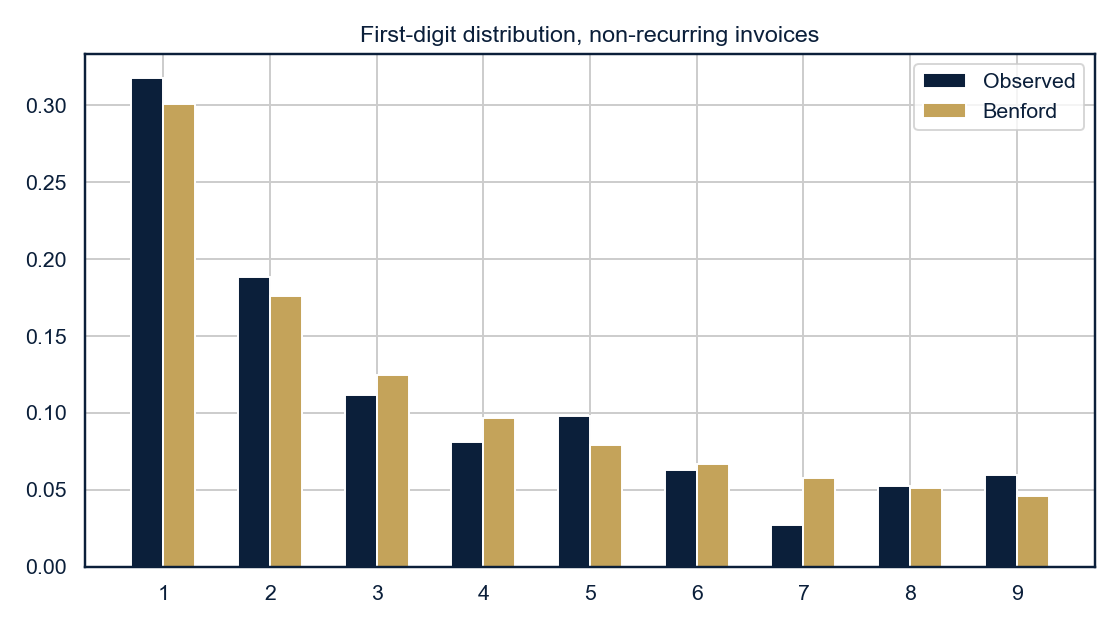

In [6]:
metric_columns = ['rule_code', 'positives', 'predicted', 'true_positives', 'false_positives', 'false_negatives', 'precision', 'recall', 'f1_score', 'benign_controls_flagged']
display(metrics[metric_columns])
print('unweighted_mean_f1', round(float(metrics['f1_score'].mean()), 4))
print('invoice_benford_n', summary['benford_invoice_sample_size'])
print('invoice_benford_mad', summary['benford_invoice_mad'])
print('invoice_benford_p_value', summary['benford_invoice_p_value'])
print('invoice_benford_band', summary['benford_invoice_band'])
display(Image(filename=str(root / 'screenshots' / '05_benford_invoices.png')))

## Invoice investigation

<a id="invoice-investigation"></a>

One flagged invoice alert and the invoice rows named in its stored evidence. The evidence text is the JSON written by the detector.

In [7]:
flagged = alerts[(alerts['entity_type'] == 'invoice') & (alerts['estimated_exposure_inr'] > 0)].sort_values('alert_id').iloc[0]
evidence = json.loads(flagged['supporting_evidence'])
display(flagged[['alert_id', 'rule_name', 'entity_id', 'vendor_id', 'severity', 'estimated_exposure_inr', 'detection_reason', 'review_status']].to_frame().T)
print(flagged['supporting_evidence'])
related = invoices[invoices['invoice_id'].isin(evidence['invoice_ids'])][
    ['invoice_id', 'invoice_number', 'vendor_id', 'invoice_date', 'total_amount_inr', 'status', 'dispute_flag']
]
display(related)

,alert_id,rule_name,entity_id,vendor_id,severity,estimated_exposure_inr,detection_reason,review_status
59,ALT000060,Exact duplicate invoice number,INV000241,VEN052,High,49560.0,More than one invoice uses the same vendor and invoice number.,Pending Review


{"anchor_invoice_id": "INV000240", "invoice_ids": ["INV000240", "INV000241"], "invoice_numbers": ["SA2-2023-10001", "SA2-2023-10001"], "totals_inr": [49560.0, 49560.0], "vendor_id": "VEN052"}


,invoice_id,invoice_number,vendor_id,invoice_date,total_amount_inr,status,dispute_flag
229,INV000240,SA2-2023-10001,VEN052,2023-07-04,49560.0,Paid,False
230,INV000241,SA2-2023-10001,VEN052,2023-07-05,49560.0,Approved,False
